# Are La Liga Betting Odds Accurate?

**Mac Mckay** · CS 82A Final Project · Santa Monica College

## Overview

If the bookmakers give a team a 60% chance to win, do teams like that actually win 60% of the time? To find out, I took 26 seasons of La Liga results and betting odds (2000/01 to 2025/26), turned the odds into probabilities, and compared them with what really happened. I also checked whether the odds are off in a consistent way for favorites, underdogs, or draws.

**Data:** [football-data.co.uk](https://www.football-data.co.uk/spainm.php), one CSV per season. The site provides the data free for private, non-commercial use.

## Setup

In [1]:
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = Path("data/raw")
CLEAN_DIR = Path("data/clean")
FIG_DIR = Path("figures")
for folder in [RAW_DIR, CLEAN_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## Getting the Data

The site publishes one CSV per season, named with both years combined (`0001` = 2000/01, `2526` = 2025/26). This cell downloads all 26 seasons into `data/raw/` the first time it runs and skips any file that is already there. I left out 2026/27 because that season is still being played.

In [2]:
SEASON_CODES = [f"{y:02d}{y + 1:02d}" for y in range(0, 26)]
BASE_URL = "https://www.football-data.co.uk/mmz4281/{code}/SP1.csv"

for code in SEASON_CODES:
    path = RAW_DIR / f"SP1_{code}.csv"
    if not path.exists():
        request = urllib.request.Request(BASE_URL.format(code=code), headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request) as response:
            path.write_bytes(response.read())

print(len(list(RAW_DIR.glob("SP1_*.csv"))), "season files ready")

26 season files ready


## Loading and Stacking the Seasons

Two files did not load with a plain `pd.read_csv`. Some rows in the 2004/05 file end with extra empty commas, so I strip those off. The two newest files start with a hidden character (a BOM), which reading with `utf-8-sig` takes care of. After that, I stack all 26 seasons into one table.

In [3]:
def load_season(code):
    text = (RAW_DIR / f"SP1_{code}.csv").read_text(encoding="utf-8-sig", errors="replace")
    lines = text.splitlines()
    header, rows = lines[0], lines[1:]
    rows = [row.rstrip(",") for row in rows if row.replace(",", "").strip()]
    season = pd.read_csv(io.StringIO("\n".join([header] + rows))).copy()
    season.insert(0, "Season", f"20{code[:2]}/{code[2:]}")
    return season


raw = pd.concat([load_season(code) for code in SEASON_CODES], ignore_index=True, sort=False)
print(raw.shape[0], "matches,", raw.shape[1], "columns")

9880 matches, 214 columns


## Cleaning (with a Log)

Each file has odds from several bookmakers. For example, `B365H`, `B365D`, and `B365A` are Bet365's odds for a home win, a draw, and an away win. The list of bookmakers changes over the years, so for each match **I average the odds across every bookmaker listed**. That way the method is the same for all 26 seasons.

Every cleaning step records how many rows went in and out, so the log at the end shows exactly what changed.

In [4]:
BOOKMAKERS = ["B365", "BW", "GB", "IW", "LB", "PS", "WH", "SJ", "VC", "SB", "SO", "SY",
              "BS", "BF", "1XB", "BFD", "BMGM", "BV", "CL"]
books = [b for b in BOOKMAKERS if all(f"{b}{o}" in raw.columns for o in "HDA")]
odds_cols = {o: [f"{b}{o}" for b in books] for o in "HDA"}
all_odds_cols = odds_cols["H"] + odds_cols["D"] + odds_cols["A"]

cleaning_log = []


def log_step(step, before, after, note=""):
    cleaning_log.append({"step": step, "rows_before": before, "rows_after": after,
                         "rows_removed": before - after, "note": note})


df = raw[["Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"] + all_odds_cols].copy()
log_step("Keep result + bookmaker odds columns", len(raw), len(df),
         f"{raw.shape[1]} columns down to {df.shape[1]}, {len(books)} bookmakers")

before = len(df)
df["HomeTeam"] = df["HomeTeam"].astype(str).str.strip()
df["AwayTeam"] = df["AwayTeam"].astype(str).str.strip()
df["FTR"] = df["FTR"].astype(str).str.strip().str.upper()
df = df[df["FTR"].isin(["H", "D", "A"])].copy()
log_step("Drop matches without a H/D/A result", before, len(df))

before = len(df)
dates = df["Date"]
df["Date"] = pd.to_datetime(dates, format="%d/%m/%y", errors="coerce").fillna(
    pd.to_datetime(dates, format="%d/%m/%Y", errors="coerce"))
log_step("Parse dates (dd/mm/yy and dd/mm/yyyy)", before, len(df), f"{df['Date'].isna().sum()} failed")

before = len(df)
df[all_odds_cols] = df[all_odds_cols].apply(pd.to_numeric, errors="coerce")
impossible = (df[all_odds_cols] <= 1).sum().sum()
df[all_odds_cols] = df[all_odds_cols].where(df[all_odds_cols] > 1)
log_step("Set impossible odds (<= 1.0) to missing", before, len(df), f"{impossible} values changed")

for o in "HDA":
    df[f"odds_{o}"] = df[odds_cols[o]].mean(axis=1)

before = len(df)
df = df.dropna(subset=["odds_H", "odds_D", "odds_A"])
log_step("Drop matches with no odds from any bookmaker", before, len(df))

before = len(df)
df = df.drop_duplicates(subset=["Season", "HomeTeam", "AwayTeam"])
log_step("Drop duplicate matches", before, len(df))

df = df.drop(columns=all_odds_cols).sort_values("Date").reset_index(drop=True)
pd.DataFrame(cleaning_log)

,step,rows_before,rows_after,rows_removed,note
0,Keep result + bookmaker odds columns,9880,9880,0,"214 columns down to 64, 19 bookmakers"
1,Drop matches without a H/D/A result,9880,9880,0,
2,Parse dates (dd/mm/yy and dd/mm/yyyy),9880,9880,0,0 failed
3,Set impossible odds (<= 1.0) to missing,9880,9880,0,0 values changed
4,Drop matches with no odds from any bookmaker,9880,9878,2,
5,Drop duplicate matches,9878,9878,0,


**Check:** a La Liga season has 20 teams and 380 matches.

In [5]:
check = df.groupby("Season").agg(matches=("FTR", "size"), teams=("HomeTeam", "nunique"))
print("Every season has 20 teams:", (check["teams"] == 20).all())
print("Seasons with fewer than 380 matches:", check[check["matches"] != 380]["matches"].to_dict())

Every season has 20 teams: True
Seasons with fewer than 380 matches: {'2000/01': 379, '2002/03': 379}


## Turning Odds into Probabilities

Decimal odds of 2.50 mean the bookmaker thinks the chance is about 1 / 2.50 = 40%.

If you do that for all three outcomes, they add up to **more than 100%**. That extra part is the **bookmaker's margin**, which is how they make money no matter who wins. To get fair probabilities, I divide each one by the total so the three add up to exactly 100%.

For example: odds of 2.00 / 3.40 / 3.80 give 50.0% + 29.4% + 26.3% = 105.7%. Dividing each by 1.057 gives **47.3% / 27.8% / 24.9%**, and the margin is 5.7%.

In [6]:
total = 1 / df["odds_H"] + 1 / df["odds_D"] + 1 / df["odds_A"]
for o in "HDA":
    df[f"prob_{o}"] = (1 / df[f"odds_{o}"]) / total
df["margin_pct"] = (total - 1) * 100

df.to_csv(CLEAN_DIR / "laliga_matches_clean.csv", index=False)
df[["Season", "HomeTeam", "AwayTeam", "FTR", "odds_H", "odds_D", "odds_A",
    "prob_H", "prob_D", "prob_A", "margin_pct"]].head().round(3)

,Season,HomeTeam,AwayTeam,FTR,odds_H,odds_D,odds_A,prob_H,prob_D,prob_A,margin_pct
0,2000/01,Barcelona,Malaga,H,1.292,4.156,8.080,0.680,0.211,0.109,13.837
1,2000/01,La Coruna,Ath Bilbao,H,1.542,3.350,5.340,0.572,0.263,0.165,13.428
2,2000/01,Real Madrid,Valencia,H,1.626,3.300,4.510,0.540,0.266,0.195,13.977
3,2000/01,Sociedad,Santander,D,1.800,3.210,3.700,0.488,0.274,0.238,13.735
4,2000/01,Zaragoza,Espanol,A,1.710,3.170,4.212,0.514,0.277,0.209,13.767


## Question 1: When the Odds Say X%, Does It Happen X% of the Time?

Every match gives three predictions (home win, draw, away win). I group all of them into 10% buckets (0–10%, 10–20%, and so on) and compare the average predicted chance with how often the outcome actually happened. If the odds are accurate, the dots should land on the diagonal line.

- **Error bars** are 95% confidence intervals for the actual rate.
- **z-score** measures how far the actual rate is from the predicted one, compared to normal random variation. If |z| > 1.96, the gap is too big to be just luck (at the 5% level).

In [7]:
predictions = pd.concat([
    pd.DataFrame({"prob": df[f"prob_{o}"], "odds": df[f"odds_{o}"], "happened": (df["FTR"] == o).astype(int)})
    for o in "HDA"
], ignore_index=True)


def compare(group):
    n = len(group)
    predicted = group["prob"].mean()
    actual = group["happened"].mean()
    return pd.Series({
        "count": n,
        "predicted_%": predicted * 100,
        "actual_%": actual * 100,
        "gap": (actual - predicted) * 100,
        "ci_95": 1.96 * np.sqrt(actual * (1 - actual) / n) * 100,
        "z": (actual - predicted) / np.sqrt(predicted * (1 - predicted) / n),
    })


predictions["bucket"] = pd.cut(predictions["prob"], bins=np.arange(0, 1.01, 0.1))
buckets = predictions.groupby("bucket", observed=True)[["prob", "happened"]].apply(compare)
buckets = buckets[buckets["count"] >= 50]
buckets.round(1)

,count,predicted_%,actual_%,gap,ci_95,z
bucket,,,,,,
"(0.0, 0.1]",1016.0,7.2,5.7,-1.5,1.4,-1.8
"(0.1, 0.2]",3675.0,15.6,14.4,-1.2,1.1,-1.9
"(0.2, 0.3]",12005.0,26.4,25.5,-0.9,0.8,-2.2
"(0.3, 0.4]",4992.0,34.4,34.2,-0.2,1.3,-0.3
"(0.4, 0.5]",3519.0,44.7,46.7,1.9,1.6,2.3
"(0.5, 0.6]",2179.0,54.6,55.9,1.4,2.1,1.3
"(0.6, 0.7]",1246.0,64.6,66.9,2.4,2.6,1.8
"(0.7, 0.8]",690.0,74.6,79.6,5.0,3.0,3.0
"(0.8, 0.9]",293.0,84.5,89.1,4.5,3.6,2.1


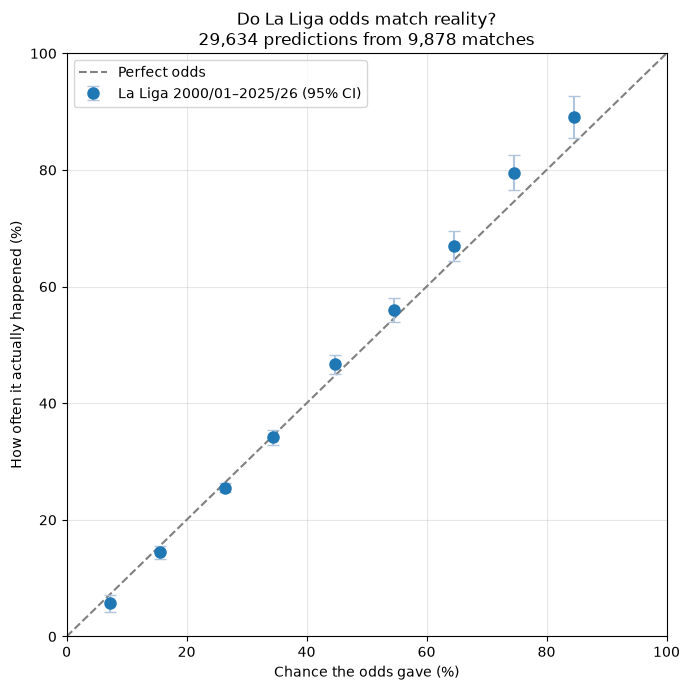

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Perfect odds")
ax.errorbar(buckets["predicted_%"], buckets["actual_%"], yerr=buckets["ci_95"],
            fmt="o", markersize=8, color="tab:blue", ecolor="lightsteelblue", capsize=4,
            label="La Liga 2000/01–2025/26 (95% CI)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("Chance the odds gave (%)")
ax.set_ylabel("How often it actually happened (%)")
ax.set_title(f"Do La Liga odds match reality?\n{len(predictions):,} predictions from {len(df):,} matches")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "1_odds_vs_reality.png", dpi=150)
plt.show()

**My take:** Overall, La Liga odds are well calibrated: the dots stay close to the "perfect odds" line. The gaps follow a pattern, though. Outcomes the odds gave less than a 30% chance (mostly underdogs and draws) happened slightly *less* often than predicted, while outcomes above 40% (mostly favorites) happened *more* often. The biggest gaps are for heavy favorites: teams given 70–80% actually won 79.6% of the time (z = 3.0). This is the classic **favorite–longshot bias**: strong favorites win more often than the odds suggest, and long shots win less.

## Question 2: Favorites, Draws, and Underdogs

For each match, the **favorite** is the team the odds gave the higher chance to win, and the **underdog** is the other team. For each group, I compare what the odds said with what actually happened, using the same z-test.

In [9]:
home_fav = df["prob_H"] >= df["prob_A"]
fav_won = np.where(home_fav, df["FTR"] == "H", df["FTR"] == "A")
dog_won = np.where(home_fav, df["FTR"] == "A", df["FTR"] == "H")

roles = pd.concat([
    pd.DataFrame({"role": "Favorite", "prob": np.where(home_fav, df["prob_H"], df["prob_A"]), "happened": fav_won}),
    pd.DataFrame({"role": "Draw", "prob": df["prob_D"], "happened": df["FTR"] == "D"}),
    pd.DataFrame({"role": "Underdog", "prob": np.where(home_fav, df["prob_A"], df["prob_H"]), "happened": dog_won}),
], ignore_index=True)
roles["happened"] = roles["happened"].astype(int)

order = ["Favorite", "Draw", "Underdog"]
role_table = roles.groupby("role")[["prob", "happened"]].apply(compare).loc[order]
role_table.round(2)

,count,predicted_%,actual_%,gap,ci_95,z
role,,,,,,
Favorite,9878.0,51.38,53.37,1.99,0.98,3.95
Draw,9878.0,25.95,25.19,-0.76,0.86,-1.72
Underdog,9878.0,22.67,21.44,-1.23,0.81,-2.92


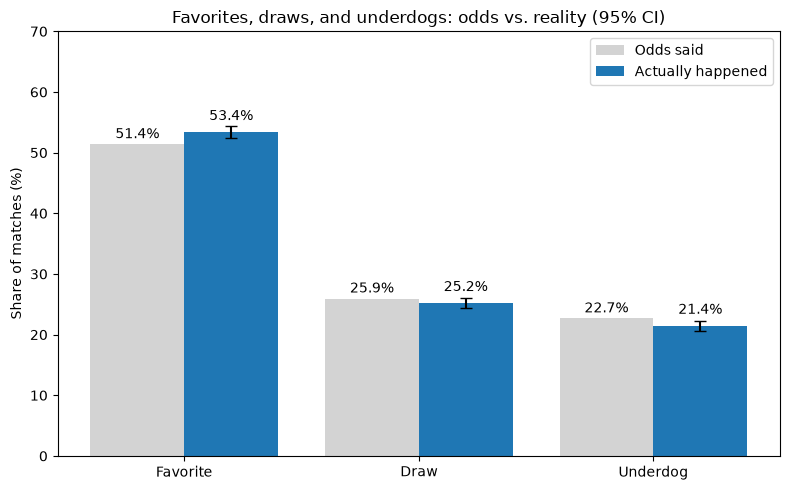

In [10]:
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - 0.2, role_table["predicted_%"], 0.4, label="Odds said", color="lightgray")
ax.bar(x + 0.2, role_table["actual_%"], 0.4, label="Actually happened", color="tab:blue",
       yerr=role_table["ci_95"], capsize=4)
for i, role in enumerate(order):
    ax.text(i - 0.2, role_table.loc[role, "predicted_%"] + 1, f"{role_table.loc[role, 'predicted_%']:.1f}%", ha="center")
    ax.text(i + 0.2, role_table.loc[role, "actual_%"] + 2, f"{role_table.loc[role, 'actual_%']:.1f}%", ha="center")
ax.set_xticks(x)
ax.set_xticklabels(order)
ax.set_ylabel("Share of matches (%)")
ax.set_ylim(0, 70)
ax.set_title("Favorites, draws, and underdogs: odds vs. reality (95% CI)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "2_favorites_draws_underdogs.png", dpi=150)
plt.show()

**My take:** This chart confirms the favorite–longshot bias from the chart 1. Favorites won 53.4% of the time when the odds said 51.4% (+2.0 points), and underdogs won 21.4% when the odds said 22.7% (-1.2 points). Both gaps are larger than their 95% confidence intervals (z = 3.95 and -2.92), so they are very unlikely to be luck. Draws also came in a bit lower than predicted (-0.8 points), but that gap is not statistically significant (z = -1.72). In short, bookmakers slightly overprice underdogs and slightly underprice favorites.

## The Bookmakers' Cut Over Time

This is the bookmaker's margin from the "Turning Odds into Probabilities" step, averaged by season. Has the cut that bookmakers build into the odds changed since 2000?

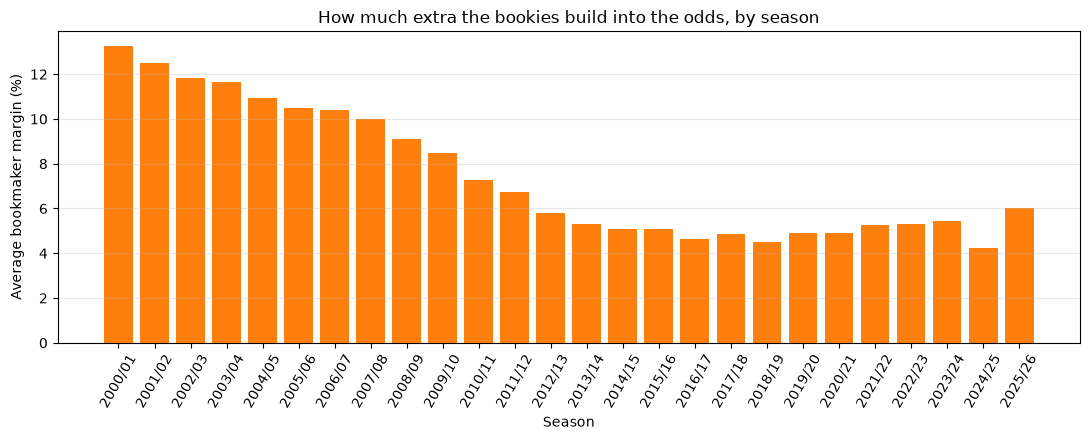

2000/01: 13.3%   2025/26: 6.0%


In [11]:
margin = df.groupby("Season")["margin_pct"].mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(margin.index, margin.values, color="tab:orange")
ax.set_ylabel("Average bookmaker margin (%)")
ax.set_xlabel("Season")
ax.set_title("How much extra the bookies build into the odds, by season")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "3_bookie_margin_by_season.png", dpi=150)
plt.show()

print(f"{margin.index[0]}: {margin.iloc[0]:.1f}%   {margin.index[-1]}: {margin.iloc[-1]:.1f}%")

**My take:** The bookmakers' margin has dropped a lot since 2000. It was highest at the start of the data, 13.3% in 2000/01, and stayed around 10% or higher through 2007/08. It then fell steadily for several seasons and has stayed roughly between 4% and 5.5% since 2013/14, with 2025/26 coming in at 6.0%. Bettors today pay less than half the cut they paid in 2000.

## Key Numbers

In [12]:
print(f"Matches: {len(df):,} ({df['Season'].min()} to {df['Season'].max()})")
for role in order:
    r = role_table.loc[role]
    print(f"{role:9s} odds said {r['predicted_%']:.1f}%, actually {r['actual_%']:.1f}% (z = {r['z']:.2f})")
print(f"Bookie margin: {margin.iloc[0]:.1f}% -> {margin.iloc[-1]:.1f}%")

Matches: 9,878 (2000/01 to 2025/26)
Favorite  odds said 51.4%, actually 53.4% (z = 3.95)
Draw      odds said 25.9%, actually 25.2% (z = -1.72)
Underdog  odds said 22.7%, actually 21.4% (z = -2.92)
Bookie margin: 13.3% -> 6.0%


## Limitations

1. **The data can't explain why the margin dropped.** The chart shows the margin falling from 13.3% to about 4–6%, but the CSVs only contain results and odds. Explaining *why* (more competition, online betting, and so on) would need outside industry sources.

2. **Averaged odds are not real odds.** To get one line per match, I averaged the odds from every bookmaker in the file. No bettor can actually place a bet at that average, so real results for a bettor would depend on which bookmaker they used.

3. **How the margin is removed matters.** I removed the margin proportionally across home, draw, and away. Bookmakers may not spread their margin evenly (they might add more of it to long shots), so part of the favorite–longshot bias I found could come from this method. A different method could make the gap a little smaller.

## AI Use

I used Claude to help write and debug the code for downloading, cleaning, analyzing, and charting the data, and to help polish the wording of this report. Every prompt is logged in `prompt_log.md`. The research question, the choices about what to check, and the takeaways are mine, and I checked the key results against the tables in this notebook.